In [1]:
# Cell 0: required header (name + library versions)
YOUR_NAME = "Nitya Dhagat (200483337)"
import torch, transformers
print("Name:", YOUR_NAME)
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)

Name: Nitya Dhagat (200483337)
torch: 2.14.1+cu130
transformers: 5.22.1


# PA2 Part 3: Dissecting a Pretrained LLM (Pythia-160m-deduped)

**What this notebook does.** We open up `EleutherAI/pythia-160m-deduped` (12 layers, 12 heads, d = 768) and ask two questions:

1. **Where and when does a prediction form?** We read the model's hidden state after every layer with the *logit lens* and track how that changes across six pretraining checkpoints (Sections 3.2.1 and 3.2.2).
2. **Are layers from different moments of training interchangeable?** We swap single components of the final model with the same component from earlier checkpoints and measure the damage (Section 3.3).

**Contents:** 3.1 Reading Pythia | 3.2.1 Watch a prediction form | 3.2.2 Across training | 3.3 Transplanting layers across time

**To reproduce:** run on a GPU (Colab T4). Upload `test_LM_obama.txt` to `/content/` (or edit `OBAMA_PATH`). Use *Runtime > Run all* once, in a fresh session. About 4 GB of checkpoints are downloaded.

**Data / evaluation set used everywhere:** the whole of `test_LM_obama.txt`, tokenised with the Pythia tokenizer and cut into non-overlapping 256-token chunks (remainder dropped). All accuracies and losses below are averages over the same chunks, so every number is directly comparable.

In [2]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"       # keep the exported PDF clean
import gc, math, random
import numpy as np, pandas as pd
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import FancyBboxPatch
import transformers
from transformers import AutoTokenizer, GPTNeoXForCausalLM
transformers.utils.logging.disable_progress_bar()
transformers.utils.logging.set_verbosity_error()

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

NAME = "EleutherAI/pythia-160m-deduped"
OBAMA_PATH = "/content/test_LM_obama.txt" if os.path.exists("/content/test_LM_obama.txt") else "test_LM_obama.txt"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU (this will be slow)")

tok = AutoTokenizer.from_pretrained(NAME)

def load(step):
    m = GPTNeoXForCausalLM.from_pretrained(NAME, revision=f"step{step}", torch_dtype=torch.float32)
    return m.to(device).eval()

def cleanup():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

# ---- evaluation data: whole Obama test file -> 256-token chunks ----
text = open(OBAMA_PATH, encoding="utf-8").read()
all_ids = tok(text, return_tensors="pt").input_ids[0]
CHUNK = 256
n_chunks = len(all_ids) // CHUNK
chunks = all_ids[: n_chunks * CHUNK].view(n_chunks, CHUNK)
print(f"{len(text.split())} words -> {len(all_ids)} Pythia tokens -> {n_chunks} chunks of {CHUNK} "
      f"({len(all_ids) - n_chunks * CHUNK} tokens dropped); {n_chunks * (CHUNK - 1)} next-token predictions per evaluation")
print("first chunk, decoded (first 200 chars):", repr(tok.decode(chunks[0])[:200]))

device: cuda | Tesla T4


4820 words -> 6017 Pythia tokens -> 23 chunks of 256 (129 tokens dropped); 5865 next-token predictions per evaluation
first chunk, decoded (first 200 chars): "The third source of tension is our shared interest in the rights and responsibilities of nations on nuclear weapons.\nI'm grateful for your hospitality and the hospitality of the people of Egypt.\nIt sh"


## 3.1 Reading Pythia

> Answer each question in your own words (a few sentences), citing the section numbers from Biderman et al. (2023). Replace the italic prompts below.
>
> *Useful facts to check in the paper before you write:* the paper's three case studies are (a) mitigating gender bias, (b) memorization as a Poisson point process, and (c) term-frequency effects on few-shot performance. Decide which of them *needs* intermediate checkpoints plus a fixed data order, and which one could be run with only the final model. For Q2, look at where the paper compares the standard and deduplicated models and note what it reports.

**1. Why checkpoints? (2 pts)**

*YOUR ANSWER HERE: name the case study that depends most on the shared data order and checkpoints, and the one that could mostly be done with the final model; justify each in a sentence, citing the paper's sections.*

**2. Data (2 pts)**

*YOUR ANSWER HERE: one finding from the deduped vs. non-deduped comparison, with the section it comes from.*

## 3.2 The Logit Lens: Reading Predictions Layer by Layer

**Idea.** The model only reads out a prediction from the top: `logits = W_U · LN_f(h_L)`. Nothing stops us from applying the same readout to the hidden state `h_l` after *any* layer `l`. `l = 0` is the embedding output, `l = 12` is the real output. The cell below draws the pipeline, then we check the one subtle implementation detail: whether `hidden_states[-1]` already includes the final LayerNorm.

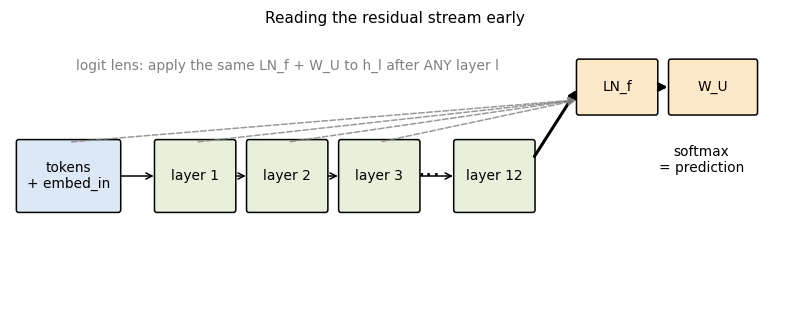

In [3]:
# Figure: the logit-lens pipeline
fig, ax = plt.subplots(figsize=(9, 3.4)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 3.4)
def box(x, y, w, h, t, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03", fc=fc, ec="k", lw=1))
    ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=9)
box(0.1, 1.3, 1.3, 0.8, "tokens\n+ embed_in", "#dde8f7")
for i, x in enumerate([1.9, 3.1, 4.3]):
    box(x, 1.3, 1.0, 0.8, f"layer {i+1}", "#e8f0dc")
ax.text(5.45, 1.7, "...", fontsize=16, ha="center")
box(5.8, 1.3, 1.0, 0.8, "layer 12", "#e8f0dc")
box(7.4, 2.45, 1.0, 0.6, "LN_f", "#fde9c9"); box(8.6, 2.45, 1.1, 0.6, "W_U", "#fde9c9")
ax.text(9.0, 1.75, "softmax\n= prediction", ha="center", fontsize=9)
for x0, x1 in [(1.4, 1.9), (2.9, 3.1), (4.1, 4.3), (5.3, 5.8)]:
    ax.annotate("", (x1, 1.7), (x0, 1.7), arrowprops=dict(arrowstyle="->"))
# real readout (top) and lens readouts (dashed, from intermediate layers)
ax.annotate("", (7.4, 2.75), (6.8, 1.9), arrowprops=dict(arrowstyle="->", lw=2))
ax.annotate("", (8.6, 2.75), (8.4, 2.75), arrowprops=dict(arrowstyle="->", lw=2))
for x in [0.75, 2.4, 3.6, 4.8]:
    ax.annotate("", (7.4, 2.6), (x, 2.1), arrowprops=dict(arrowstyle="->", ls="--", color="gray", alpha=.8))
ax.text(3.6, 2.95, "logit lens: apply the same LN_f + W_U to h_l after ANY layer l", color="gray", fontsize=9, ha="center")
ax.set_title("Reading the residual stream early", fontsize=10); plt.show()

layers=12  heads=12  d=768  vocab=50304  params=162.3M  tied embeddings=False
max |W_U(h_L)        - logits| = 0.00e+00
max |W_U(LN_f(h_L))  - logits| = 3.81e+01


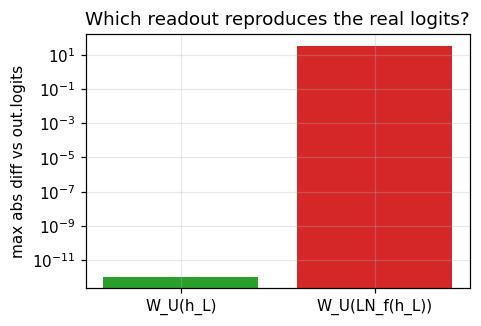

=> hidden_states[-1] already has LN_f applied: True (so the lens applies LN_f to layers 0..11 only)


In [4]:
def get_readout(model):
    return model.gpt_neox.final_layer_norm, model.get_output_embeddings()

@torch.no_grad()
def check_last_hidden_has_ln(model, ids):
    """Is hidden_states[-1] already LN_f-normalised? Compare both readouts with out.logits."""
    ln_f, W_U = get_readout(model)
    out = model(ids, output_hidden_states=True)
    h = out.hidden_states[-1]
    no_ln = (W_U(h) - out.logits).abs().max().item()
    with_ln = (W_U(ln_f(h)) - out.logits).abs().max().item()
    print(f"max |W_U(h_L)        - logits| = {no_ln:.2e}")
    print(f"max |W_U(LN_f(h_L))  - logits| = {with_ln:.2e}")
    plt.figure(figsize=(4.5, 3)); plt.bar(["W_U(h_L)", "W_U(LN_f(h_L))"], [max(no_ln, 1e-12), with_ln], color=["tab:green", "tab:red"])
    plt.yscale("log"); plt.ylabel("max abs diff vs out.logits"); plt.title("Which readout reproduces the real logits?"); plt.show()
    return no_ln < with_ln

@torch.no_grad()
def lens_logits(model, hidden_states, last_has_ln):
    """Lens logits for every layer 0..L: list of L+1 tensors (B, T, V). LN_f is applied exactly once per layer."""
    ln_f, W_U = get_readout(model)
    L = len(hidden_states) - 1
    return [W_U(h) if (l == L and last_has_ln) else W_U(ln_f(h)) for l, h in enumerate(hidden_states)]

final = load(143000)
cfg = final.config
print(f"layers={cfg.num_hidden_layers}  heads={cfg.num_attention_heads}  d={cfg.hidden_size}  vocab={cfg.vocab_size}  "
      f"params={sum(p.numel() for p in final.parameters())/1e6:.1f}M  tied embeddings={cfg.tie_word_embeddings}")
LAST_HAS_LN = check_last_hidden_has_ln(final, chunks[:1].to(device))
print("=> hidden_states[-1] already has LN_f applied:", LAST_HAS_LN, "(so the lens applies LN_f to layers 0..11 only)")

In [5]:
@torch.no_grad()
def metrics(model, batch_size=4):
    """Per-layer lens statistics over all chunks (layers 0..L):
         acc  : top-1 accuracy for the true next token
         ce   : mean cross-entropy -log p(true next token)
         kl   : KL( final-layer distribution || lens distribution at layer l )
         norm : mean L2 norm of the hidden state h_l   (note: h_L is post-LN_f in HF)"""
    ln_f, W_U = get_readout(model); L = model.config.num_hidden_layers
    acc, ce, kl, nrm = (np.zeros(L + 1) for _ in range(4)); n = 0
    for i in range(0, len(chunks), batch_size):
        ids = chunks[i:i + batch_size].to(device); tgt = ids[:, 1:]
        hs = model(ids, output_hidden_states=True).hidden_states
        def logp(l):
            h = hs[l]; use_ln = not (l == L and LAST_HAS_LN)
            return F.log_softmax((W_U(ln_f(h) if use_ln else h))[:, :-1].float(), -1)
        lp_final = logp(L); p_final = lp_final.exp()
        for l in range(L + 1):
            lq = lp_final if l == L else logp(l)
            acc[l] += (lq.argmax(-1) == tgt).sum().item()
            ce[l] += -lq.gather(-1, tgt.unsqueeze(-1)).sum().item()
            kl[l] += (p_final * (lp_final - lq)).sum().item()
            nrm[l] += hs[l][:, :-1].norm(dim=-1).sum().item()
        n += tgt.numel()
    return dict(acc=acc / n, ce=ce / n, kl=kl / n, norm=nrm / n)

M = {143000: metrics(final)}      # metrics for every checkpoint, filled in below
print("lens statistics computed for step143000")

lens statistics computed for step143000


### 3.2.1 Watch a prediction form

Each cell of the grids shows the lens's **top-1 token** at that layer and input position (predicting the *next* word). The shade is the probability the lens gives to the **true** next token (yellow = confident and correct, purple = ~0). The last position has no true next token, so its shade is blank.

11 tokens: They have not served a Red America or a Blue America
12 tokens: We will rebuild this economy so that everyone gets a fair shot
columns: 0:They | 1:have | 2:not | 3:served | 4:a | 5:Red | 6:America | 7:or | 8:a | 9:Blue | 10:America


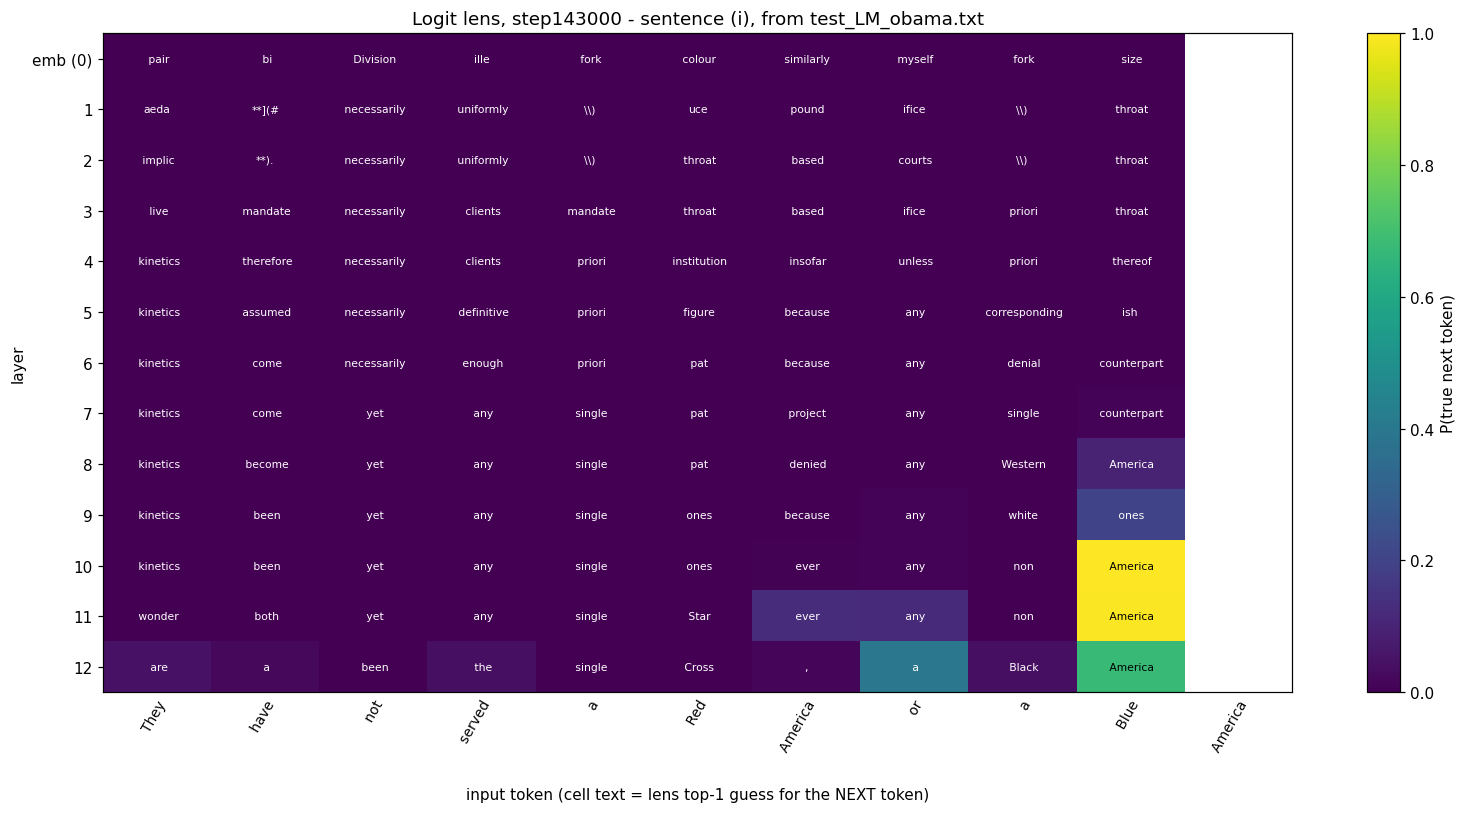

columns: 0:We | 1:will | 2:rebuild | 3:this | 4:economy | 5:so | 6:that | 7:everyone | 8:gets | 9:a | 10:fair | 11:shot


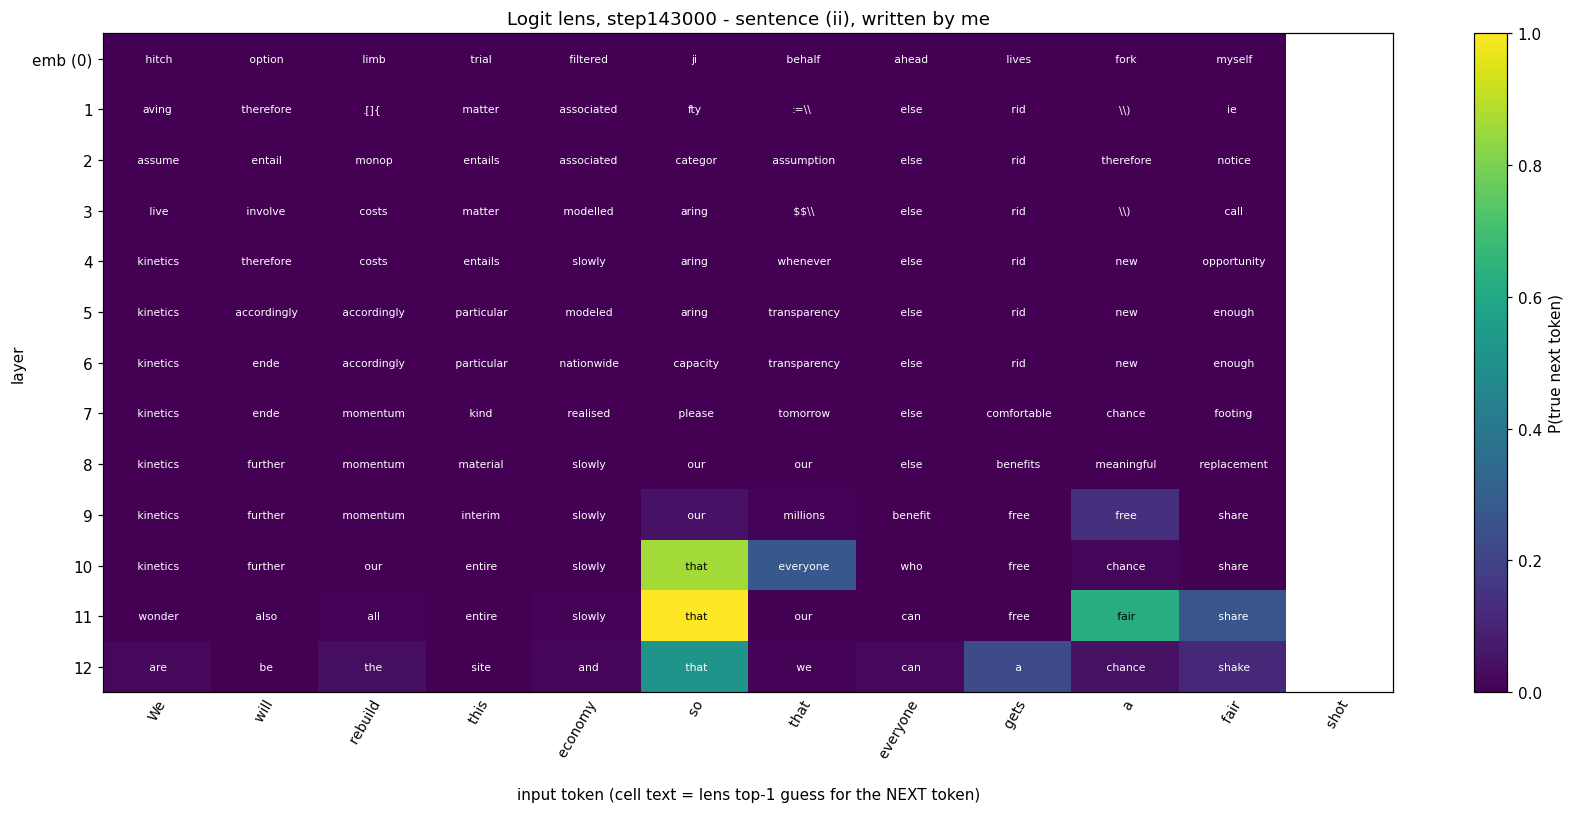

In [6]:
def esc(s):
    """matplotlib treats $...$ as math text; escape literal dollar signs in token labels."""
    return s.replace("$", chr(92) + "$")

@torch.no_grad()
def plot_lens_grid(model, sentence, title):
    ids = tok(sentence, return_tensors="pt").input_ids.to(device)
    hs = model(ids, output_hidden_states=True).hidden_states
    logits = lens_logits(model, hs, LAST_HAS_LN)
    T = ids.shape[1]; nxt = ids[0, 1:]
    probs = np.full((len(logits), T), np.nan); tops = []
    for l, lg in enumerate(logits):
        p = lg[0].softmax(-1)
        tops.append([tok.decode(i) for i in p.argmax(-1).tolist()])
        probs[l, :T - 1] = p[torch.arange(T - 1), nxt].cpu().numpy()
    fig, ax = plt.subplots(figsize=(1.15 * T + 2, 7.5)); ax.grid(False)
    im = ax.imshow(probs, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    for l in range(len(logits)):
        for t in range(T):
            v = probs[l, t]; c = "k" if (not np.isnan(v) and v > 0.55) else "w"
            ax.text(t, l, esc(repr(tops[l][t])[1:-1]), ha="center", va="center", fontsize=7, color=c)
    # token labels drawn as plain text under each column (robust: no tick-label machinery)
    labels = [esc(repr(tok.decode([int(i)]))[1:-1]) for i in ids[0].tolist()]
    assert len(labels) == T == probs.shape[1]
    ax.set_xticks([])
    for t, lab in enumerate(labels):
        ax.text(t, len(logits) - 0.4, lab, rotation=60, ha="right", va="top", rotation_mode="anchor", fontsize=9, clip_on=False)
    print("columns:", " | ".join(f"{t}:{lab.strip()}" for t, lab in enumerate(labels)))
    ax.set_yticks(range(len(logits))); ax.set_yticklabels(["emb (0)"] + [str(i) for i in range(1, len(logits))])
    ax.set_xlabel("input token (cell text = lens top-1 guess for the NEXT token)", labelpad=62); ax.set_ylabel("layer")
    ax.set_title(title); fig.colorbar(im, ax=ax, label="P(true next token)")
    plt.tight_layout(); plt.show()

@torch.no_grad()
def topk_table(model, sentence, pos, layers=(0, 4, 8, 10, 11, 12), k=5):
    """Top-k lens guesses at one input position, for a few layers (the 'zoomed-in' view of a grid column)."""
    ids = tok(sentence, return_tensors="pt").input_ids.to(device)
    lgs = lens_logits(model, model(ids, output_hidden_states=True).hidden_states, LAST_HAS_LN)
    true_id = ids[0, pos + 1]; rows = []
    for l in layers:
        p = lgs[l][0, pos].softmax(-1); top = p.topk(k)
        rows.append({"layer": l, f"top-{k} lens guesses (prob)": ", ".join(f"{tok.decode(i)!r}:{v:.2f}" for v, i in zip(top.values.tolist(), top.indices.tolist())),
                     f"P(true={tok.decode(true_id)!r})": p[true_id].item(), "rank of true": int((p > p[true_id]).sum().item()) + 1})
    return pd.DataFrame(rows).set_index("layer")

sent1 = "They have not served a Red America or a Blue America"
assert sent1 in text, "sentence (i) must come from test_LM_obama.txt"
sent2 = "We will rebuild this economy so that everyone gets a fair shot"   # <-- REPLACE with a sentence you wrote yourself (10-15 tokens)
for s in (sent1, sent2):
    n = len(tok(s).input_ids); print(f"{n:2d} tokens: {s}" + ("" if 10 <= n <= 15 else "   <-- outside the 10-15 token range!"))

plot_lens_grid(final, sent1, "Logit lens, step143000 - sentence (i), from test_LM_obama.txt")
plot_lens_grid(final, sent2, "Logit lens, step143000 - sentence (ii), written by me")

In [7]:
# Zoom into one column of grid (i): the position of " Blue", whose true next token is " America"
ids1 = tok(sent1).input_ids; pos = len(ids1) - 2
print(f"input position {pos} = {tok.decode(ids1[pos])!r}, true next token = {tok.decode(ids1[pos+1])!r}")
topk_table(final, sent1, pos)

input position 9 = ' Blue', true next token = ' America'


,top-5 lens guesses (prob),P(true=' America'),rank of true
layer,,,
0,"' size':0.43, ' proportional':0.24, 'cal':0.14...",0.0000,30379
4,"' thereof':0.67, 'ish':0.29, ' Belt':0.01, ' g...",0.0000,2975
8,"' America':0.10, ' suprem':0.10, ' stratified'...",0.0970,1
10,"' America':1.00, ' American':0.00, ' ones':0.0...",0.9971,1
11,"' America':0.99, ' American':0.00, ' Or':0.00,...",0.9937,1
12,"' America':0.68, ' one':0.03, ' American':0.02...",0.6767,1


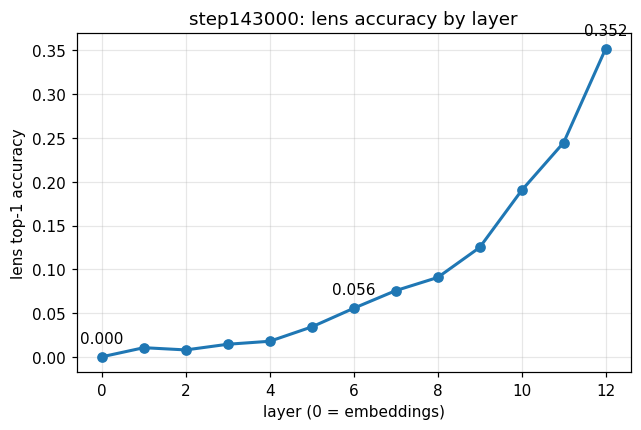

step143000, layer  0: top-1 accuracy = 0.0002
step143000, layer  6: top-1 accuracy = 0.0556
step143000, layer 12: top-1 accuracy = 0.3517


In [8]:
# REQUIRED: lens top-1 accuracy vs layer over all of test_LM_obama.txt (step143000)
acc_final = M[143000]["acc"]
plt.figure(figsize=(6.5, 4)); plt.plot(range(13), acc_final, "o-", lw=2)
for l in (0, 6, 12): plt.annotate(f"{acc_final[l]:.3f}", (l, acc_final[l]), textcoords="offset points", xytext=(0, 9), ha="center")
plt.xlabel("layer (0 = embeddings)"); plt.ylabel("lens top-1 accuracy"); plt.title("step143000: lens accuracy by layer"); plt.show()
for l in (0, 6, 12):
    print(f"step143000, layer {l:2d}: top-1 accuracy = {acc_final[l]:.4f}")

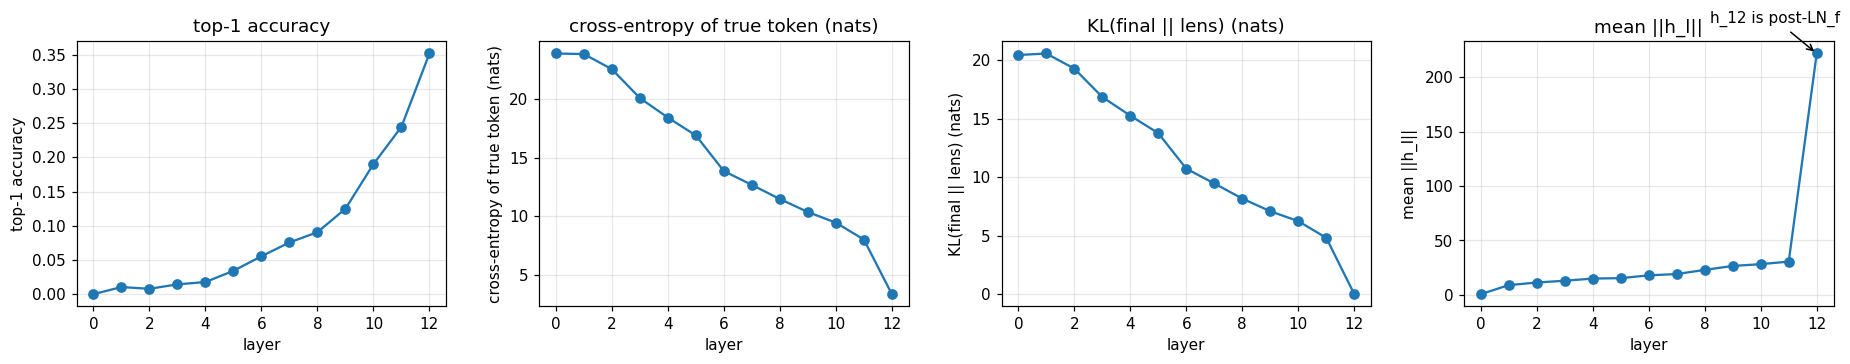

            acc      ce      kl     norm
layer 0  0.0002 23.8842 20.4597   0.6931
layer 1  0.0106 23.8358 20.5897   8.9778
layer 2  0.0080 22.5461 19.2921  11.3796
layer 3  0.0145 20.0853 16.8650  13.0265
layer 4  0.0179 18.4215 15.2715  15.0208
layer 5  0.0343 16.9002 13.7704  15.4097
layer 6  0.0556 13.8577 10.7336  17.9660
layer 7  0.0757 12.6873  9.4703  19.1670
layer 8  0.0907 11.4777  8.1758  22.9917
layer 9  0.1250 10.3763  7.0931  26.6022
layer 10 0.1901  9.4634  6.2481  28.2546
layer 11 0.2447  8.0280  4.8183  30.5999
layer 12 0.3517  3.3719  0.0000 221.7728


In [9]:
# EXTRA: three views of the same final model -> accuracy is not the whole story
m = M[143000]; fig, axs = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, key, yl in zip(axs, ["acc", "ce", "kl", "norm"],
                       ["top-1 accuracy", "cross-entropy of true token (nats)", "KL(final || lens) (nats)", "mean ||h_l||"]):
    ax.plot(range(13), m[key], "o-"); ax.set_xlabel("layer"); ax.set_ylabel(yl); ax.set_title(yl)
axs[3].annotate("h_12 is post-LN_f", (12, m["norm"][12]), textcoords="offset points", xytext=(-70, 20), arrowprops=dict(arrowstyle="->"))
plt.tight_layout(); plt.show()
print(pd.DataFrame(m, index=[f"layer {l}" for l in range(13)]))

**Notes on 3.2.1** (your analysis of the two grids and the curve; it must match the figures above)

*YOUR ANSWER HERE. Things to describe, using what you actually see: (a) at which layers do the first correct top-1 guesses appear, and what do the early-layer guesses look like (garbage tokens? copies of the input?); (b) how the shade changes with layer; (c) the accuracy at layers 0, 6 and 12 printed above; (d) the shape of the curve between layers 6 and 12 and what the CE and KL panels add; (e) any position where the model is wrong at the top but was right earlier (or vice versa).*

### 3.2.2 Across training

We repeat the lens statistics at all six checkpoints. The **required figure** uses step512, 1000, 8000 and 143000 on the same axes; since step0 and step32000 are needed for Section 3.3 anyway, we also show them in the extra figures.

In [10]:
STEPS_ALL = [0, 512, 1000, 8000, 32000, 143000]
del final; cleanup()
for s in STEPS_ALL:
    if s in M: continue
    mdl = load(s); M[s] = metrics(mdl); del mdl; cleanup()
    print(f"step{s}: done  (layer 0/6/12 acc = {M[s]['acc'][0]:.4f} / {M[s]['acc'][6]:.4f} / {M[s]['acc'][12]:.4f})")

step0: done  (layer 0/6/12 acc = 0.0002 / 0.0000 / 0.0000)
step512: done  (layer 0/6/12 acc = 0.0005 / 0.1158 / 0.2063)
step1000: done  (layer 0/6/12 acc = 0.0003 / 0.1599 / 0.2471)
step8000: done  (layer 0/6/12 acc = 0.0005 / 0.1589 / 0.3381)
step32000: done  (layer 0/6/12 acc = 0.0003 / 0.1507 / 0.3480)


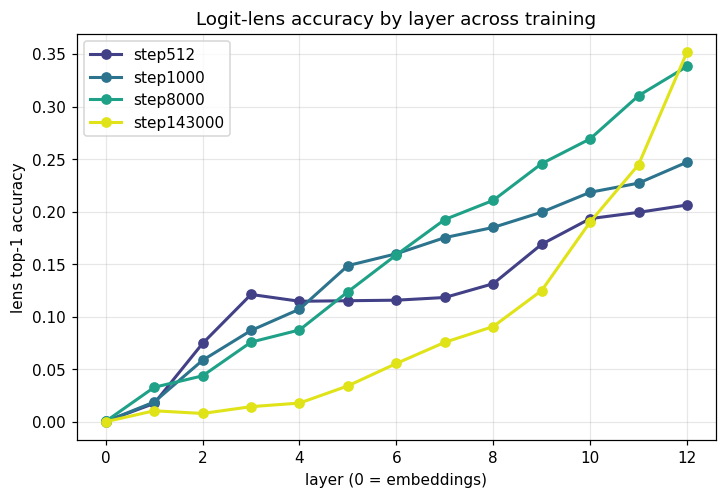

step   512: layer  0 = 0.0005   layer  6 = 0.1158   layer 12 = 0.2063
step  1000: layer  0 = 0.0003   layer  6 = 0.1599   layer 12 = 0.2471
step  8000: layer  0 = 0.0005   layer  6 = 0.1589   layer 12 = 0.3381
step143000: layer  0 = 0.0002   layer  6 = 0.0556   layer 12 = 0.3517


In [11]:
# REQUIRED figure: accuracy by layer at step512, 1000, 8000, 143000 on the same axes
STEPS_LENS = [512, 1000, 8000, 143000]
colors = dict(zip(STEPS_ALL, plt.cm.viridis(np.linspace(0, 0.95, len(STEPS_ALL)))))
plt.figure(figsize=(7.5, 4.8))
for s in STEPS_LENS: plt.plot(range(13), M[s]["acc"], "o-", color=colors[s], lw=2, label=f"step{s}")
plt.xlabel("layer (0 = embeddings)"); plt.ylabel("lens top-1 accuracy"); plt.legend(); plt.title("Logit-lens accuracy by layer across training"); plt.show()
for s in STEPS_LENS: print(f"step{s:>6}: " + "   ".join(f"layer {l:2d} = {M[s]['acc'][l]:.4f}" for l in (0, 6, 12)))

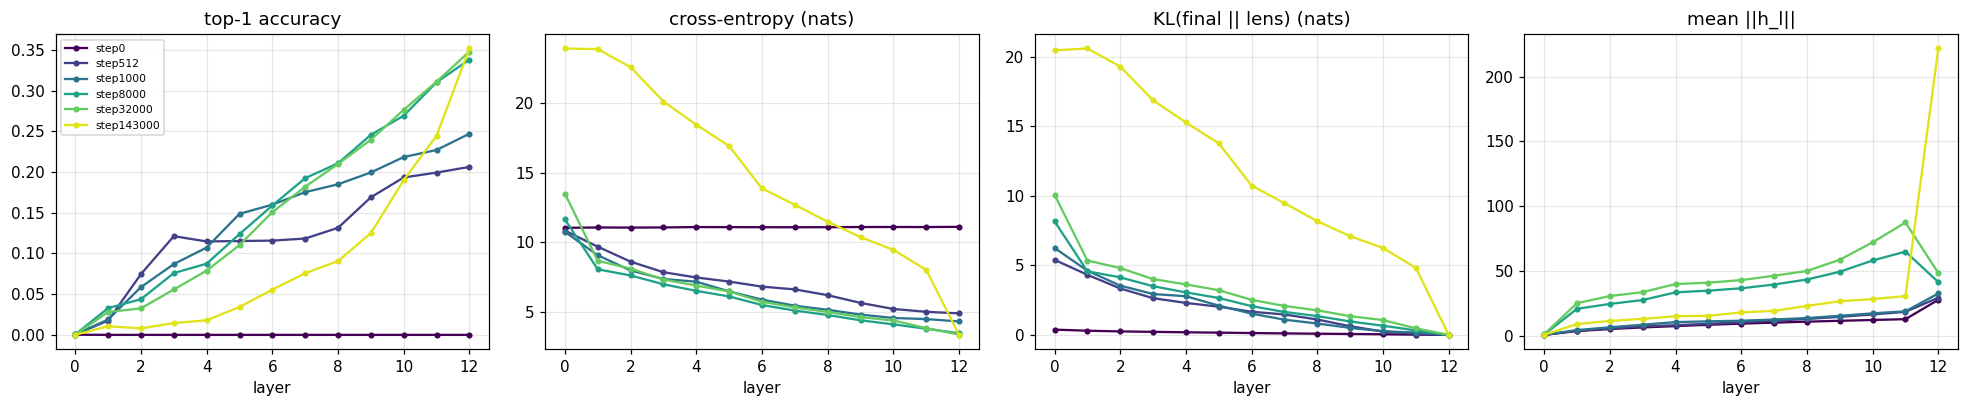

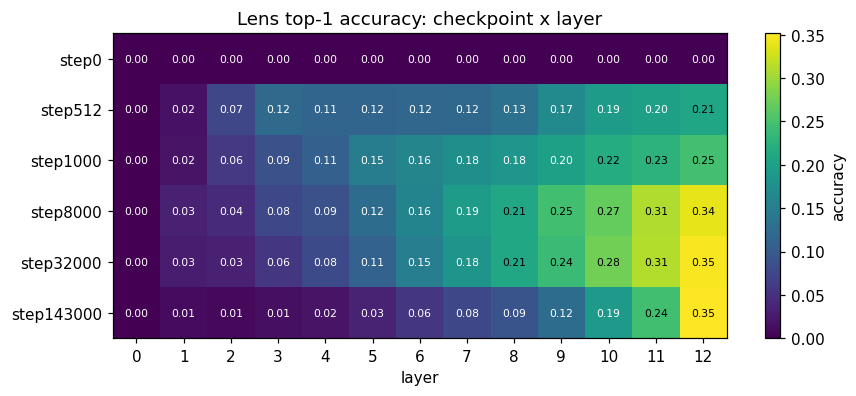

,layer 0 acc,layer 6 acc,layer 12 acc,mean acc layers 4-8,KL at layer 6,CE at layer 6,CE at layer 12
step0,0.0002,0.0000,0.0000,0.0000,0.1312,11.0822,11.1107
step512,0.0005,0.1158,0.2063,0.1191,1.6621,6.8281,4.9115
step1000,0.0003,0.1599,0.2471,0.1552,1.5264,5.8965,4.3357
step8000,0.0005,0.1589,0.3381,0.1547,2.0673,5.5104,3.4885
step32000,0.0003,0.1507,0.3480,0.1464,2.5194,5.7454,3.3941
step143000,0.0002,0.0556,0.3517,0.0548,10.7336,13.8577,3.3719


In [12]:
# EXTRA 1: all six checkpoints, four statistics
fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, key, yl in zip(axs, ["acc", "ce", "kl", "norm"], ["top-1 accuracy", "cross-entropy (nats)", "KL(final || lens) (nats)", "mean ||h_l||"]):
    for s in STEPS_ALL: ax.plot(range(13), M[s][key], "o-", ms=3, color=colors[s], label=f"step{s}")
    ax.set_xlabel("layer"); ax.set_title(yl)
axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()

# EXTRA 2: checkpoint x layer heatmap of lens accuracy (the same data as a picture of 'when is each layer readable')
A = np.array([M[s]["acc"] for s in STEPS_ALL])
fig, ax = plt.subplots(figsize=(9, 3.6)); ax.grid(False)
im = ax.imshow(A, cmap="viridis", aspect="auto")
ax.set_xticks(range(13)); ax.set_yticks(range(len(STEPS_ALL))); ax.set_yticklabels([f"step{s}" for s in STEPS_ALL])
for i in range(A.shape[0]):
    for j in range(A.shape[1]): ax.text(j, i, f"{A[i,j]:.2f}", ha="center", va="center", fontsize=7, color="w" if A[i, j] < 0.2 else "k")
ax.set_xlabel("layer"); ax.set_title("Lens top-1 accuracy: checkpoint x layer"); fig.colorbar(im, label="accuracy"); plt.show()

# summary table used in the written answer
mid = slice(4, 9)   # layers 4..8
summary = pd.DataFrame({
    "layer 0 acc": [M[s]["acc"][0] for s in STEPS_ALL], "layer 6 acc": [M[s]["acc"][6] for s in STEPS_ALL],
    "layer 12 acc": [M[s]["acc"][12] for s in STEPS_ALL], "mean acc layers 4-8": [M[s]["acc"][mid].mean() for s in STEPS_ALL],
    "KL at layer 6": [M[s]["kl"][6] for s in STEPS_ALL], "CE at layer 6": [M[s]["ce"][6] for s in STEPS_ALL],
    "CE at layer 12": [M[s]["ce"][12] for s in STEPS_ALL]}, index=[f"step{s}" for s in STEPS_ALL])
summary

**Answer (3.2.2).** Do the middle layers become more or less readable as training goes on? What does this suggest about whether the middle hidden states are in the same "language" as the output layer?

*YOUR ANSWER HERE. Cite numbers from the required plot and the summary table above (e.g. layer-6 accuracy at each checkpoint, the layers 4-8 mean, and how layer-12 accuracy and the KL / cross-entropy columns move over the same checkpoints). Say whether the trend is monotone or not and at which checkpoint it turns. Then argue what the trend implies about the basis the middle layers use compared with the unembedding, mentioning the tuned lens of Belrose et al. (2023).*

## 3.3 Transplanting Layers Across Time

We take the final model (step143000) and replace **one component** (the input embedding, one of the 12 layers, or the unembedding) with the same component from a donor checkpoint (step0, 1000, 8000, 32000), leaving everything else untouched. The metric is the **change in test loss** on `test_LM_obama.txt` relative to the intact model. Each swap starts from the intact model: the original weights are restored before the next one, and an assertion at the end checks that.

In [13]:
@torch.no_grad()
def test_loss(model, batch_size=4):
    tot, n = 0.0, 0
    for i in range(0, len(chunks), batch_size):
        ids = chunks[i:i + batch_size].to(device)
        logits = model(ids).logits[:, :-1]
        tot += F.cross_entropy(logits.reshape(-1, logits.size(-1)), ids[:, 1:].reshape(-1), reduction="sum").item(); n += ids[:, 1:].numel()
    return tot / n

N_LAYERS = 12
final = load(143000)
UNEMB = "lm_head" if hasattr(final, "lm_head") else "embed_out"      # name differs across transformers versions
COMPONENTS = ["gpt_neox.embed_in"] + [f"gpt_neox.layers.{i}" for i in range(N_LAYERS)] + [UNEMB]
ROW_LABELS = ["embedding"] + [f"layer {i}" for i in range(N_LAYERS)] + ["unembedding"]
DONORS = [0, 1000, 8000, 32000]
print("unembedding module:", UNEMB, "| tied embeddings:", final.config.tie_word_embeddings)

base_loss = test_loss(final)
print(f"Intact step143000 test loss: {base_loss:.4f}   (perplexity {math.exp(base_loss):.2f})")
orig_state = {c: {k: v.clone() for k, v in final.get_submodule(c).state_dict().items()} for c in COMPONENTS}
n_params = {c: sum(p.numel() for p in final.get_submodule(c).parameters()) for c in COMPONENTS}
print("parameters per component:", {r: f"{n_params[c]/1e6:.2f}M" for r, c in zip(ROW_LABELS, COMPONENTS)})

def transplant(comp, donor):  final.get_submodule(comp).load_state_dict(donor.get_submodule(comp).state_dict())
def restore(comp):            final.get_submodule(comp).load_state_dict(orig_state[comp])

delta = np.zeros((len(COMPONENTS), len(DONORS)))
for j, d in enumerate(DONORS):
    donor = load(d)
    for i, c in enumerate(COMPONENTS):
        transplant(c, donor); delta[i, j] = test_loss(final) - base_loss; restore(c)
    del donor; cleanup(); print(f"donor step{d}: done")
assert abs(test_loss(final) - base_loss) < 1e-6, "model was not restored correctly"
print("restored OK: loss after all swaps =", round(test_loss(final), 6))

unembedding module: lm_head | tied embeddings: False
Intact step143000 test loss: 3.3719   (perplexity 29.14)
parameters per component: {'embedding': '38.63M', 'layer 0': '7.09M', 'layer 1': '7.09M', 'layer 2': '7.09M', 'layer 3': '7.09M', 'layer 4': '7.09M', 'layer 5': '7.09M', 'layer 6': '7.09M', 'layer 7': '7.09M', 'layer 8': '7.09M', 'layer 9': '7.09M', 'layer 10': '7.09M', 'layer 11': '7.09M', 'unembedding': '38.63M'}
donor step0: done
donor step1000: done
donor step8000: done
donor step32000: done
restored OK: loss after all swaps = 3.371948


In [14]:
# Control: a "transplant" from an identical copy of step143000 must change nothing (checks the pipeline itself)
ctrl = load(143000)
for c in (COMPONENTS[0], COMPONENTS[6], COMPONENTS[-1]):
    transplant(c, ctrl); d0 = test_loss(final) - base_loss; restore(c)
    print(f"control swap of {c:>20s} from step143000: delta loss = {d0:+.2e}")
    assert abs(d0) < 1e-4
del ctrl; cleanup()

control swap of    gpt_neox.embed_in from step143000: delta loss = +0.00e+00
control swap of    gpt_neox.layers.5 from step143000: delta loss = +0.00e+00
control swap of              lm_head from step143000: delta loss = +0.00e+00


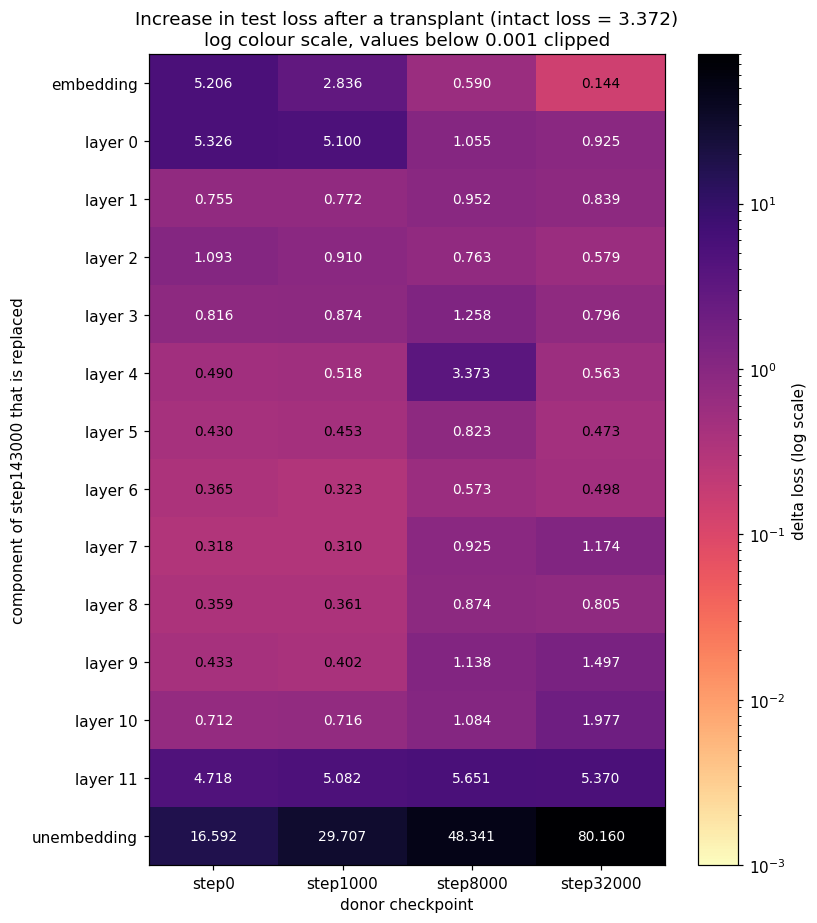

,step0,step1000,step8000,step32000
embedding,5.2056,2.8364,0.5896,0.1442
layer 0,5.3256,5.0998,1.0550,0.9253
layer 1,0.7553,0.7720,0.9520,0.8390
layer 2,1.0934,0.9098,0.7631,0.5786
layer 3,0.8161,0.8741,1.2580,0.7956
layer 4,0.4899,0.5179,3.3728,0.5629
layer 5,0.4300,0.4531,0.8229,0.4733
layer 6,0.3654,0.3227,0.5735,0.4976
layer 7,0.3179,0.3098,0.9246,1.1736
layer 8,0.3589,0.3610,0.8740,0.8047


In [15]:
# REQUIRED: component x donor heatmap (log colour scale, exact values printed in the cells)
VMIN = 1e-3
clipped = np.clip(delta, VMIN, None); norm = LogNorm(vmin=VMIN, vmax=clipped.max())
fig, ax = plt.subplots(figsize=(7.5, 8.5)); ax.grid(False)
im = ax.imshow(clipped, cmap="magma_r", norm=norm, aspect="auto")
ax.set_xticks(range(len(DONORS))); ax.set_xticklabels([f"step{d}" for d in DONORS])
ax.set_yticks(range(len(COMPONENTS))); ax.set_yticklabels(ROW_LABELS)
for i in range(len(COMPONENTS)):
    for j in range(len(DONORS)):
        ax.text(j, i, f"{delta[i, j]:.3f}", ha="center", va="center", fontsize=9, color="w" if norm(clipped[i, j]) > 0.55 else "k")
ax.set_xlabel("donor checkpoint"); ax.set_ylabel("component of step143000 that is replaced")
ax.set_title(f"Increase in test loss after a transplant (intact loss = {base_loss:.3f})\nlog colour scale, values below {VMIN} clipped")
fig.colorbar(im, ax=ax, label="delta loss (log scale)"); plt.tight_layout(); plt.show()
df_delta = pd.DataFrame(delta, index=ROW_LABELS, columns=[f"step{d}" for d in DONORS]); df_delta

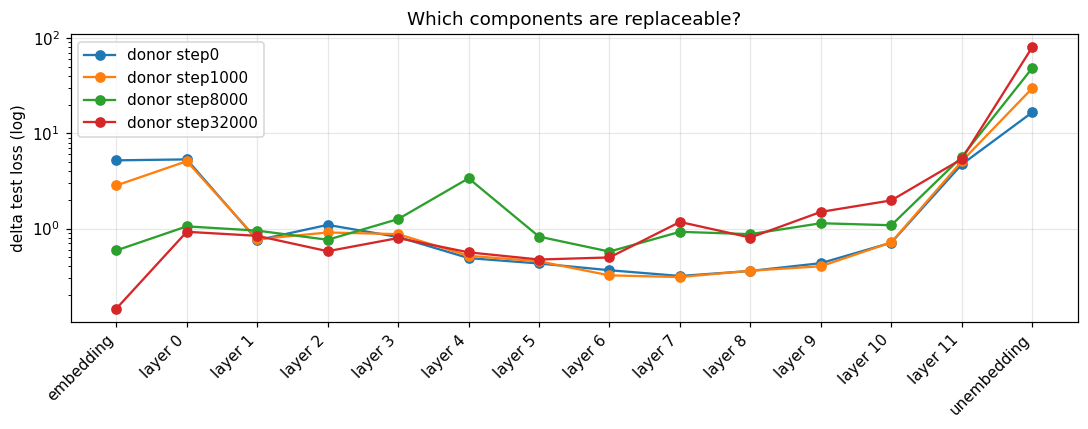

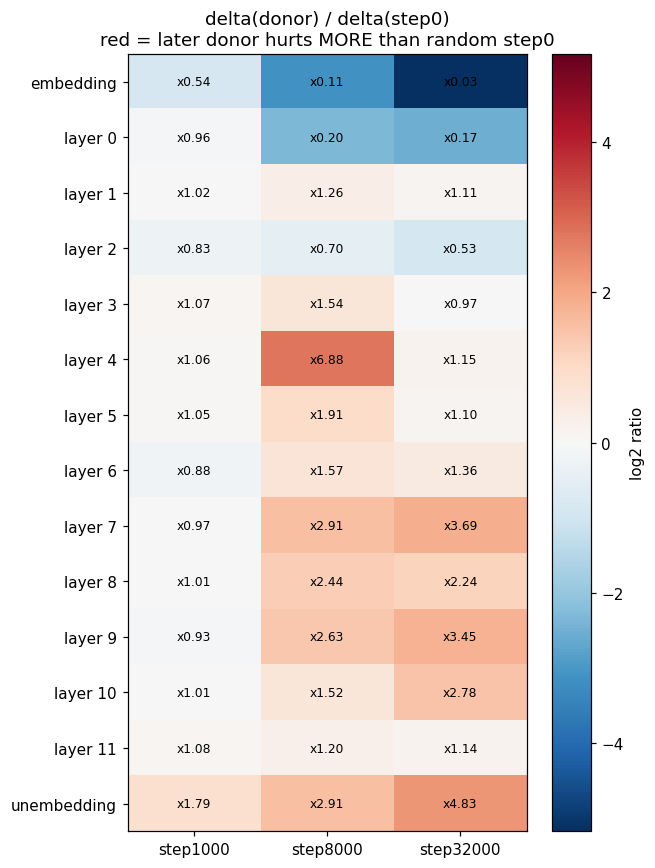

23 of 42 (component, consecutive-donor) pairs have a LATER donor hurting MORE:


,component,earlier donor,delta (earlier),later donor,delta (later),later/earlier
0,layer 4,step1000,0.5179,step8000,3.3728,6.5123
1,layer 7,step1000,0.3098,step8000,0.9246,2.9849
2,layer 9,step1000,0.4021,step8000,1.1378,2.8298
3,layer 8,step1000,0.3610,step8000,0.8740,2.4208
4,layer 10,step8000,1.0839,step32000,1.9767,1.8236
5,layer 5,step1000,0.4531,step8000,0.8229,1.8163
6,unembedding,step0,16.5921,step1000,29.7068,1.7904
7,layer 6,step1000,0.3227,step8000,0.5735,1.7774
8,unembedding,step8000,48.3406,step32000,80.1602,1.6582
9,unembedding,step1000,29.7068,step8000,48.3406,1.6273


In [16]:
# EXTRA 1: the same numbers as curves over the components, one line per donor
fig, ax = plt.subplots(figsize=(10, 4)); xs = np.arange(len(ROW_LABELS))
for j, d in enumerate(DONORS): ax.plot(xs, np.clip(delta[:, j], VMIN, None), "o-", label=f"donor step{d}")
ax.set_yscale("log"); ax.set_xticks(xs); ax.set_xticklabels(ROW_LABELS, rotation=45, ha="right")
ax.set_ylabel("delta test loss (log)"); ax.set_title("Which components are replaceable?"); ax.legend(); plt.tight_layout(); plt.show()

# EXTRA 2: where does a LATER donor hurt more than an earlier one?  ratio = delta(donor) / delta(step0)
ratio = delta[:, 1:] / delta[:, [0]]; lr = np.log2(ratio); lim = np.abs(lr).max()
fig, ax = plt.subplots(figsize=(6, 8)); ax.grid(False)
im = ax.imshow(lr, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(3)); ax.set_xticklabels([f"step{d}" for d in DONORS[1:]]); ax.set_yticks(range(len(ROW_LABELS))); ax.set_yticklabels(ROW_LABELS)
for i in range(ratio.shape[0]):
    for j in range(ratio.shape[1]): ax.text(j, i, f"x{ratio[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("delta(donor) / delta(step0)\nred = later donor hurts MORE than random step0"); fig.colorbar(im, label="log2 ratio"); plt.tight_layout(); plt.show()

# EXTRA 3: automatic check of "does a later donor always hurt less?" (consecutive donor pairs)
rows = []
for i, r in enumerate(ROW_LABELS):
    for a in range(len(DONORS) - 1):
        if delta[i, a + 1] > delta[i, a]:
            rows.append({"component": r, "earlier donor": f"step{DONORS[a]}", "delta (earlier)": delta[i, a],
                         "later donor": f"step{DONORS[a+1]}", "delta (later)": delta[i, a + 1], "later/earlier": delta[i, a + 1] / delta[i, a]})
n_pairs = len(ROW_LABELS) * (len(DONORS) - 1)
print(f"{len(rows)} of {n_pairs} (component, consecutive-donor) pairs have a LATER donor hurting MORE:")
pd.DataFrame(rows).sort_values("later/earlier", ascending=False).reset_index(drop=True)

In [17]:
# EXTRA 4: ranking by damage with the random step0 donor, and a block summary
order = np.argsort(delta[:, 0]); print("Components from least to most damaging when replaced by step0 weights:")
print(pd.DataFrame({"component": [ROW_LABELS[i] for i in order], "delta loss (step0 donor)": delta[order, 0],
                    "params (M)": [n_params[COMPONENTS[i]] / 1e6 for i in order]}).to_string(index=False))
blocks = {"embedding": [0], "layers 0-1": [1, 2], "layers 2-10 (middle)": list(range(3, 12)), "layer 11 (last)": [12], "unembedding": [13]}
print()
print(pd.DataFrame({f"step{d}": {b: delta[idx, j].mean() for b, idx in blocks.items()} for j, d in enumerate(DONORS)}))

Components from least to most damaging when replaced by step0 weights:
  component  delta loss (step0 donor)  params (M)
    layer 7                    0.3179      7.0879
    layer 8                    0.3589      7.0879
    layer 6                    0.3654      7.0879
    layer 5                    0.4300      7.0879
    layer 9                    0.4332      7.0879
    layer 4                    0.4899      7.0879
   layer 10                    0.7118      7.0879
    layer 1                    0.7553      7.0879
    layer 3                    0.8161      7.0879
    layer 2                    1.0934      7.0879
   layer 11                    4.7179      7.0879
  embedding                    5.2056     38.6335
    layer 0                    5.3256      7.0879
unembedding                   16.5921     38.6335

                       step0  step1000  step8000  step32000
embedding             5.2056    2.8364    0.5896     0.1442
layers 0-1            3.0405    2.9359    1.0035     0.882

#### Middle step: *how* does a transplant break the model?

A bigger loss number does not say where in the network things go wrong. For three representative swaps (a random-embedding swap, the biggest "later donor hurts more" cell among the non-unembedding layers, and the unembedding swap with the latest donor) we re-run the lens statistics on the damaged model and compare with the intact one. The hidden-state norms show where the damage enters the residual stream; the lens accuracy shows how much readable information survives.

cases: ['embedding <- step0 (delta 5.206)', 'layer 4 <- step8000 (delta 3.373)', 'unembedding <- step32000 (delta 80.160)']


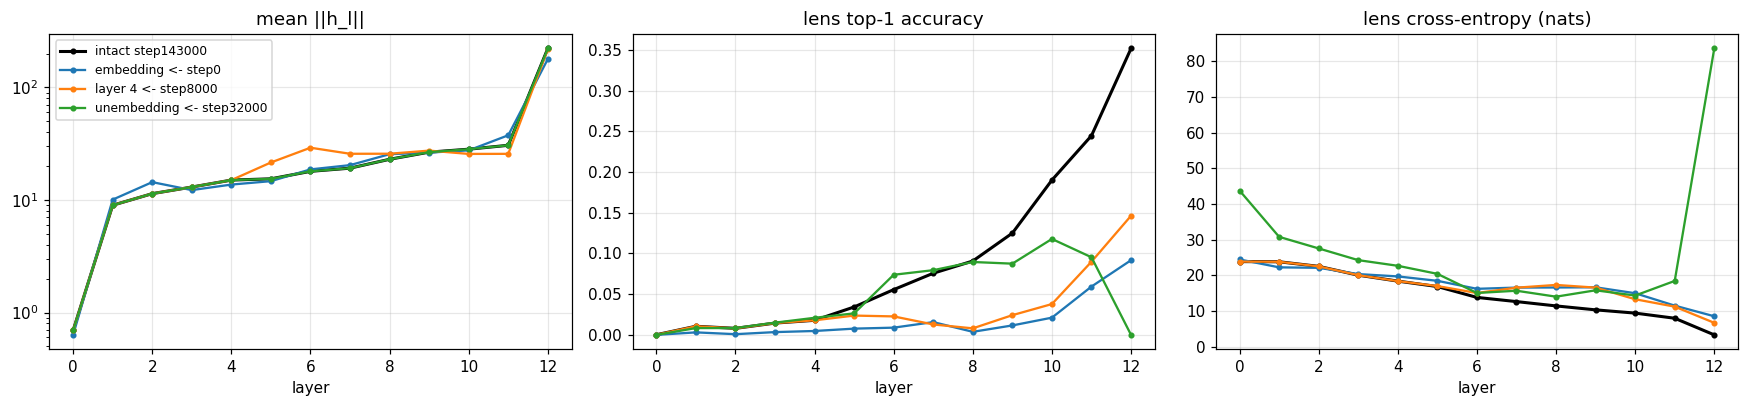

In [18]:
# pick cases automatically from the heatmap
non_unemb = delta[:-1, 1:] - delta[:-1, [0]]                 # increase of later donors over step0, excluding the unembedding row
i_a, j_a = np.unravel_index(np.argmax(non_unemb), non_unemb.shape); j_a += 1
cases = [(0, DONORS.index(0)), (int(i_a), int(j_a)), (len(COMPONENTS) - 1, len(DONORS) - 1)]
print("cases:", [f"{ROW_LABELS[i]} <- step{DONORS[j]} (delta {delta[i, j]:.3f})" for i, j in cases])

diag = {}
for d in sorted({DONORS[j] for _, j in cases}):
    donor = load(d)
    for i, j in cases:
        if DONORS[j] != d: continue
        transplant(COMPONENTS[i], donor); diag[(i, j)] = metrics(final); restore(COMPONENTS[i])
    del donor; cleanup()
assert abs(test_loss(final) - base_loss) < 1e-6

fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, key, yl in zip(axs, ["norm", "acc", "ce"], ["mean ||h_l||", "lens top-1 accuracy", "lens cross-entropy (nats)"]):
    ax.plot(range(13), M[143000][key], "k-o", lw=2, ms=3, label="intact step143000")
    for (i, j), m_ in diag.items(): ax.plot(range(13), m_[key], "o-", ms=3, label=f"{ROW_LABELS[i]} <- step{DONORS[j]}")
    ax.set_xlabel("layer"); ax.set_title(yl)
axs[0].set_yscale("log"); axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Answer (3.3).** Which components can the model lose (replaced by random step0 weights) with little damage, and which are irreplaceable? Does a later donor always hurt less than an earlier one? Explain what you find, in particular any component where a later donor hurts more.

*YOUR ANSWER HERE. Every claim needs a number from the heatmap / table / extra plots above. Checklist: (a) the least and most damaging components with step0, with their deltas (use the ranking table); (b) what the unembedding row does as the donor gets later, and why a trained-but-mismatched unembedding can be worse than a random one (think about logit scale and the output basis it expects); (c) the "later donor hurts more" table: which components, by what factor, and a hypothesis for why (use the 'how does a transplant break the model' plots as evidence, e.g. the hidden-state norm or lens curves); (d) which components get steadily cheaper to swap as the donor gets later, and what that says about how fast their weights stop changing.*

## Summary of key numbers and caveats

In [19]:
print(f"Evaluation set: {n_chunks} chunks x {CHUNK-1} predictions = {n_chunks*(CHUNK-1)} next-token predictions from test_LM_obama.txt")
print(f"Intact step143000: test loss {base_loss:.4f} (perplexity {math.exp(base_loss):.2f})")
print("\nLens top-1 accuracy (layers 0 / 6 / 12):")
for s in STEPS_ALL: print(f"  step{s:>6}: {M[s]['acc'][0]:.4f} / {M[s]['acc'][6]:.4f} / {M[s]['acc'][12]:.4f}")
i_max = np.unravel_index(np.argmax(delta), delta.shape); i_min = np.unravel_index(np.argmin(delta), delta.shape)
print(f"\nLargest transplant damage : {ROW_LABELS[i_max[0]]} <- step{DONORS[i_max[1]]}: +{delta[i_max]:.3f}")
print(f"Smallest transplant damage: {ROW_LABELS[i_min[0]]} <- step{DONORS[i_min[1]]}: +{delta[i_min]:.3f}")

Evaluation set: 23 chunks x 255 predictions = 5865 next-token predictions from test_LM_obama.txt
Intact step143000: test loss 3.3719 (perplexity 29.14)

Lens top-1 accuracy (layers 0 / 6 / 12):
  step     0: 0.0002 / 0.0000 / 0.0000
  step   512: 0.0005 / 0.1158 / 0.2063
  step  1000: 0.0003 / 0.1599 / 0.2471
  step  8000: 0.0005 / 0.1589 / 0.3381
  step 32000: 0.0003 / 0.1507 / 0.3480
  step143000: 0.0002 / 0.0556 / 0.3517

Largest transplant damage : unembedding <- step32000: +80.160
Smallest transplant damage: embedding <- step32000: +0.144


**Caveats (for honesty about the evidence).** (1) All statistics come from one speech file (about 6k tokens, 23 chunks); no confidence intervals are computed, so small differences between neighbouring cells should not be over-interpreted. (2) The lens uses the model's own `LN_f` and `W_U` at every layer; the tuned lens would train an affine translator per layer and is expected to read the middle layers better. (3) Transplants change a single component at a time, so interactions between components (e.g. swapping a layer *and* its neighbours) are not measured.